### Aquire Inventory Data of Grade Crossing id's
With this, we can now see what equipment, electronics, and 

In [1]:
import pandas as pd
from sodapy import Socrata
import numpy as np

In [2]:
form54crossingids = np.load('../Data/Internal/processed/2023form54ids.npz', allow_pickle=True)
print(form54crossingids.files)
form54crossingids['arr_0']

#df = pd.DataFrame(my_array, columns = ['Column_A','Column_B','Column_C'])

form54ids = pd.DataFrame(form54crossingids['arr_0'], columns = ['crossingid'])

print(form54ids)

['arr_0']
     crossingid
0       868284G
1       910400F
2       028672M
3       271925H
4       273145P
...         ...
1363    870492H
1364    225588W
1365    147940X
1366    226610K
1367    807271N

[1368 rows x 1 columns]


In [3]:
# Assuming form54ids is your DataFrame and it has a column named 'crossingid'
list_of_ids = form54ids['crossingid'].tolist()

# Now list_of_ids is a list that contains all the crossing IDs
print(list_of_ids)


['868284G', '910400F', '028672M', '271925H', '273145P', '622148A', '624365G', '624154K', '718062K', '620052D', '961641J', '050330S', '726569B', '620162N', '603892T', '876024J', '603892T', '865575L', '307588A', '376127D', '385246L', '260601A', '916990A', '605923W', '167529J', '176911R', '176925Y', '173887G', '925769J', '243205P', '294316W', '163376U', '176974V', '294465X', '843808U', '608302L', '608311K', '260640R', '431091X', '430993Y', '079759T', '289347K', '078521J', '724599L', '326907S', '309452U', '386379G', '163413U', '163613D', '174009S', '920569H', '289550C', '079590V', '289067H', '243177N', '079534N', '480060G', '072813K', '479171C', '608846J', '173891W', '004482R', '004396U', '440521E', '353718S', '173887G', '846922E', '840417P', '176594N', '169806X', '372180B', '174991E', '174470N', '326894T', '862818B', '260541T', '295086B', '475104U', '163431S', '608310D', '608853U', '069057V', '079487H', '174592T', '801665H', '174009S', '920334X', '307168V', '307897M', '190580P', '307642R'

In [4]:
#!/usr/bin/env python

# make sure to install these packages before running:
# pip install pandas
# pip install sodapy


# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.

#results = client.get_all("m2f8-22s6", where = "crossingid = '1'")

# Convert list of IDs to a string format suitable for the query
# This transforms [1, 2, 3] into "1, 2, 3"
ids_string = ', '.join([f"'{id}'" for id in list_of_ids])

# Construct the query string
query = f"crossingid IN ({ids_string})"

# Use the client to get all the data for the constructed query
results = client.get_all("m2f8-22s6", where=query)

# Now results should contain the data for all the crossing IDs in your list

# Convert to pandas DataFrame
test = pd.DataFrame.from_records(results)

In [5]:
print(len(test['crossingid'].unique()))

1304


In [6]:
# Use isin to check for matches
matches = test['crossingid'].isin(form54ids['crossingid'])

# Sum the Boolean values to get the count of matching IDs
count_of_matching_ids = matches.sum()

print(f"Number of matching 'crossingid's: {count_of_matching_ids}")

Number of matching 'crossingid's: 1304


In [7]:
print(matches)

0       True
1       True
2       True
3       True
4       True
        ... 
1299    True
1300    True
1301    True
1302    True
1303    True
Name: crossingid, Length: 1304, dtype: bool


So we do have the inventory id's but they must be old data updates not in 2023. OKay cool. 
we could even call data only for who's id match from matches. 

In [8]:
#tabulate test
from tabulate import tabulate
print(tabulate(test, headers='keys', tablefmt='psql'))

+------+-------------------------+----------------+------------------------------------------------------------+---------------------------+-----------------------+--------------+--------------------------------+--------------+--------------------+-----------------------+----------------------------------------------------------+-------------+----------------+--------------+---------------------+--------------+----------+------------+------------------------+----------------------------------------------------------------+---------------------------------------+---------------------------+-----------------+-------------+---------------------+------------------------+------------------------+--------------------------+-----------------------------+--------------------+----------------------+---------------------+--------------------+----------------+-----------------------+-------------------+------------------------+--------------------+-------------------------+-----------------------

In [9]:
# Assuming 'test' is your DataFrame and 'crossingid' is the column of interest
# And you're looking for the value '025422p', our most frquent crossingid with incidents from form54

matching_entries = test[test['crossingid'] == '025422P']

# Now 'matching_entries' contains all rows from 'test' where 'crossingid' equals '025422p'
print(matching_entries)


               revisiondate railroadcode          railroadname  \
52  2021-08-03T00:00:00.000         BNSF  BNSF Railway Company   

   reportingagencytypecode reportingagencytype reasoncode reasondescription  \
52                       1            Railroad         14    Change in Data   

   crossingid crossingidsuffix reportingagencycode  ... crossingsurfaceid3  \
52    025422P             BNSF                BNSF  ...                NaN   

   crossingsurfacedescription3 advancewarning7 advancewarningtext7  \
52                         NaN             NaN                 NaN   

   traindetectionid3 traindetection3 sametrackrailroad4 typeoftrainserviceid4  \
52               NaN             NaN                NaN                   NaN   

   typeoftrainservice4 separatetrackrailroad2  
52                 NaN                    NaN  

[1 rows x 249 columns]


In [10]:
#Explore for NA's, missing data, and redunnacy

isnaValues = test.isna()
print(isnaValues)

# Check for NA values
missing_values = test.isna().sum()

#check for null values
missing_data = test.isnull().sum()
print(missing_data)

# Check for missing data
for column in test.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in test.columns:
    if test[column].duplicated().sum() > 0:
        print(f"The column {column} has {test[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = test.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
inventoryDataClean = test.drop(columns=drop_list)


# Check the shape of the raw data
print(f"The Raw Data Frame has {test.shape[0]} rows and {test.shape[1]} columns.")
print(f"The clean data freame has a mean of missing: {missing_values}")
print(f"\n The Raw Data Frame has {len(test.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(inventoryDataClean.columns)} labels.")
print("\n Count of labels dropped: \n", len(test.columns) - len(inventoryDataClean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", inventoryDataClean.columns.values)

      revisiondate  railroadcode  railroadname  reportingagencytypecode  \
0            False         False         False                    False   
1            False         False         False                    False   
2            False         False         False                    False   
3            False         False         False                    False   
4            False         False         False                    False   
...            ...           ...           ...                      ...   
1299         False         False         False                    False   
1300         False         False         False                    False   
1301         False         False         False                    False   
1302         False         False         False                    False   
1303         False         False         False                    False   

      reportingagencytype  reasoncode  reasondescription  crossingid  \
0                   False  

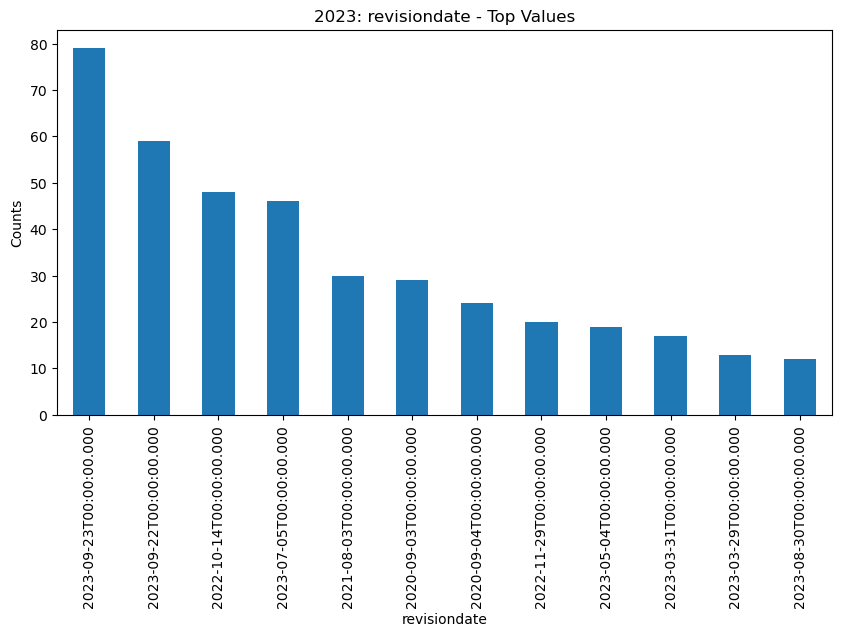

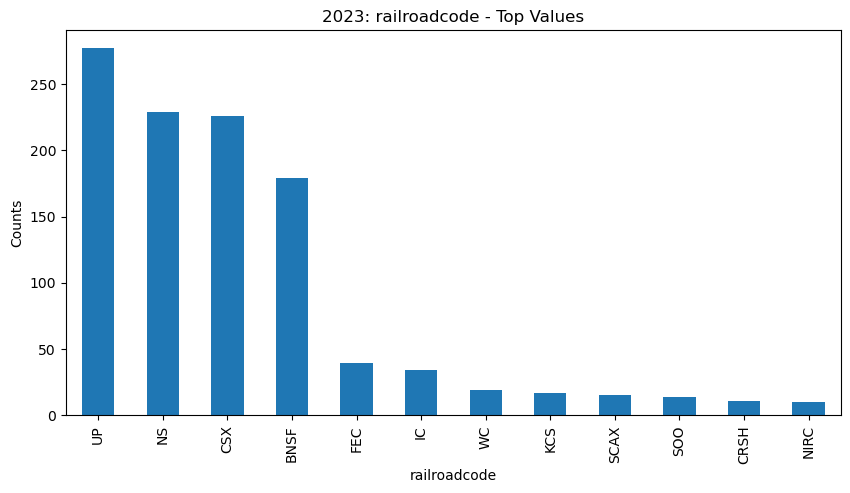

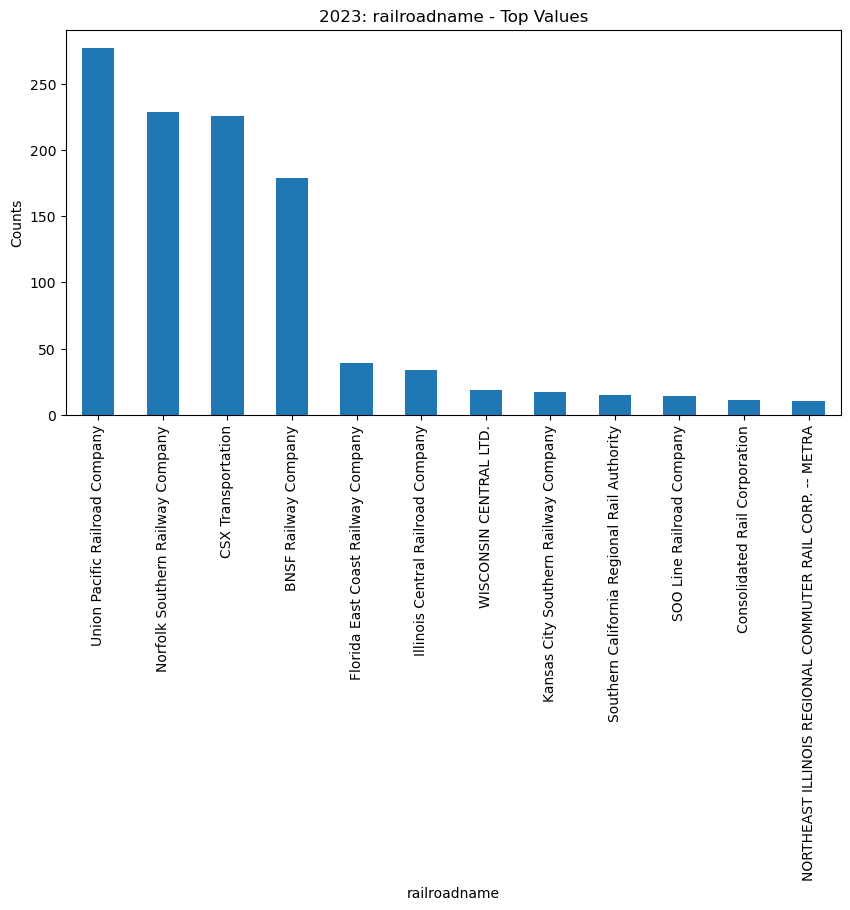

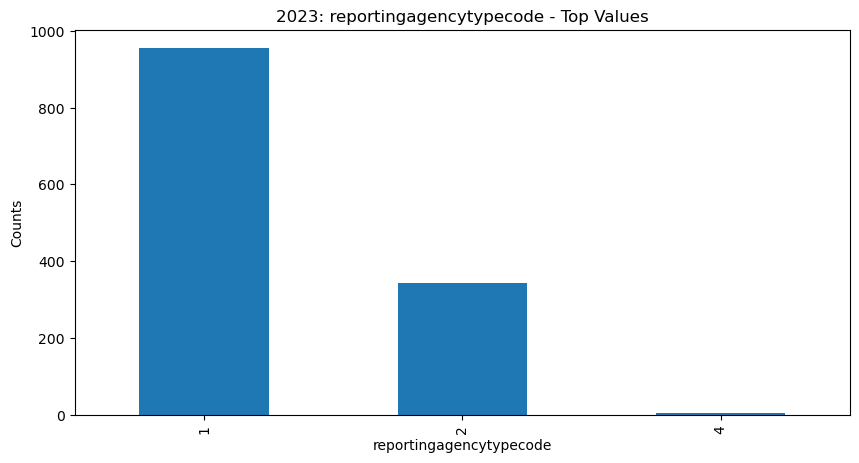

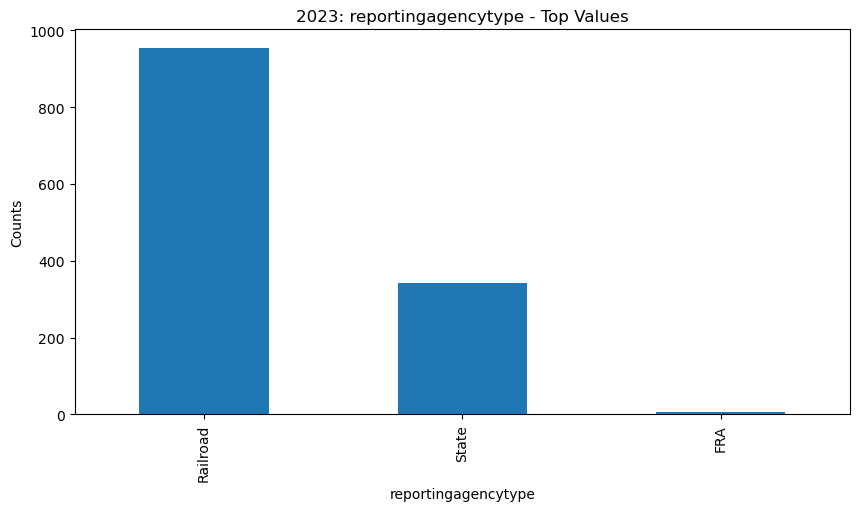

...

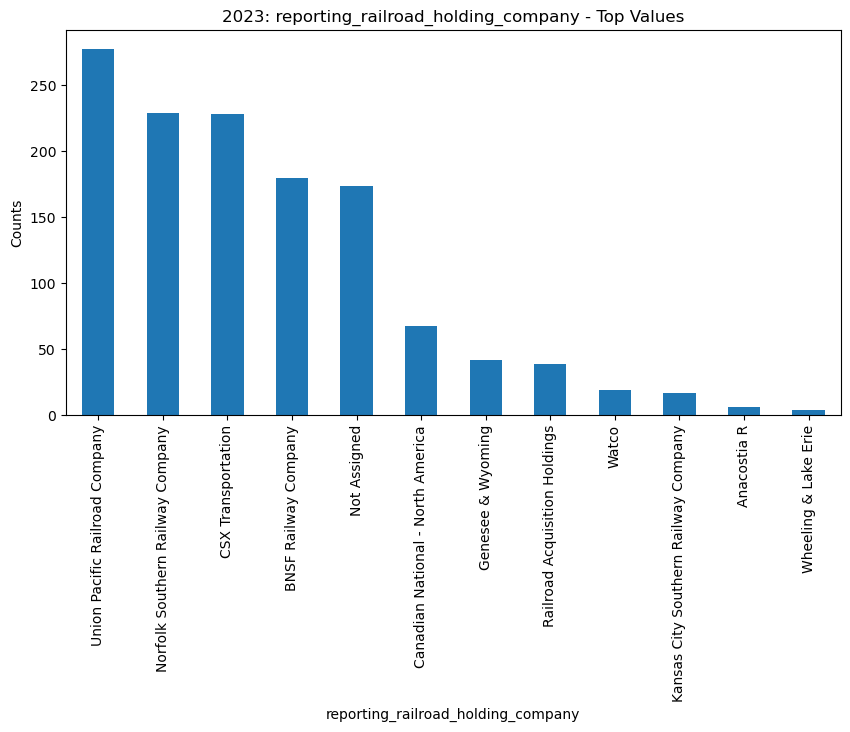

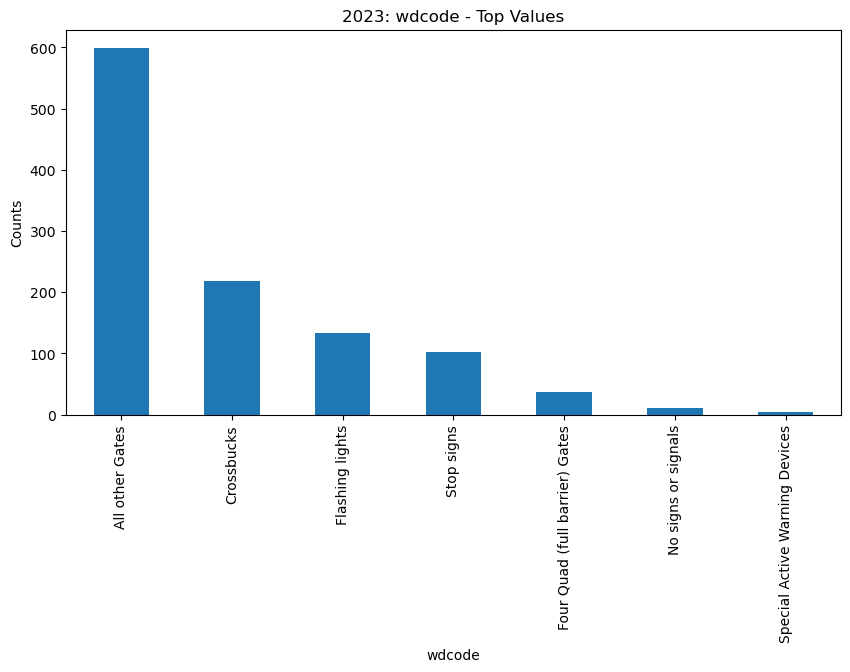

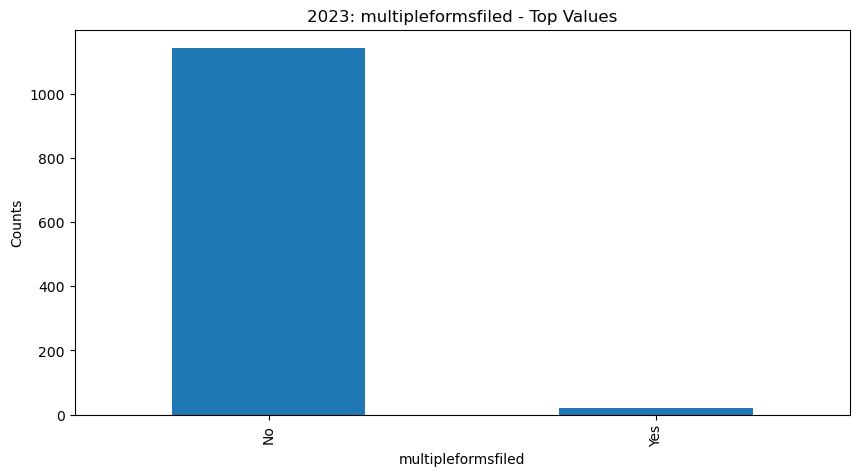

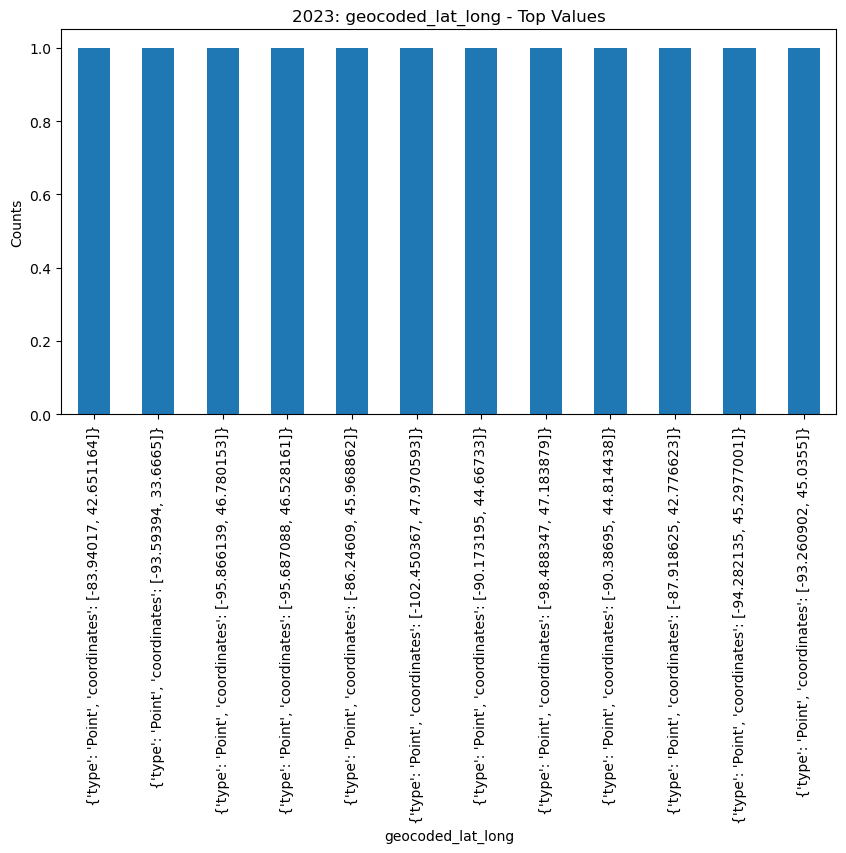

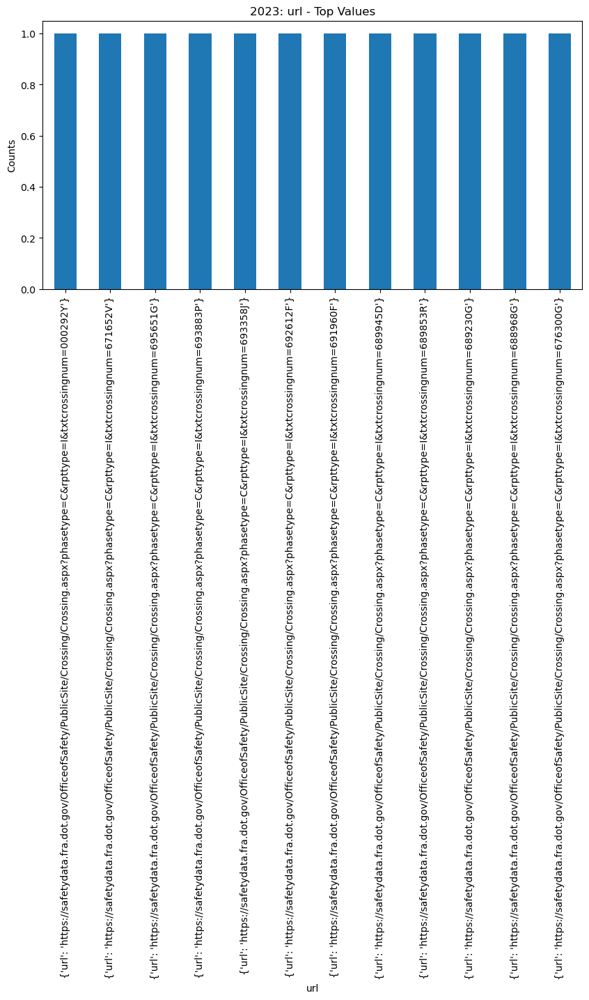

In [13]:
import matplotlib.pyplot as plt

# Iterate over each column in the DataFrame
for column in inventoryDataClean.columns:
    # Calculate the value counts of the current column
    value_counts = inventoryDataClean[column].value_counts()

    # Determine the number of unique values
    unique_values = len(value_counts)

    # If there are more than 12 unique values, select the top 12
    if unique_values > 12:
        value_counts = value_counts.head(12)

    # Create a new figure and axis for the histogram
    plt.figure(figsize=(10, 5))

    # Plot the bar chart
    value_counts.plot.bar(title=f'2023: {column} - Top Values')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Counts')

    plt.savefig(f'2023: {column} - Top Dozen Values.png', bbox_inches='tight', dpi=300) 

    # Show the plot
    plt.show()



In [12]:
np.savez('../Data/Internal/processed/2023InventoryDataClean.npz', inventoryDataClean.to_numpy())